# E-PRIOR: bad, neutral, and good location priors

100 paired linear-model trials; fixed L=3, changes at 0.30 and 0.55. Joint configuration priors are uniform over the DP-admissible pairs, then filtered by half-open 1/4-width windows, with a real 0.04 gap between the two trimmed good windows. The bad second window is centered at 0.80 and disjoint from the good second window. Each prior is explicitly marginalized into signal occupancy probabilities; those are passed to WERM and the matching conditional population-risk calculation. The population calculation is not a fixed-point theorem. Set WERM_SMOKE=1 to run two paired trials before full execution.

### Paper-ready experiment description

Across 100 paired Monte Carlo trials (base seed 20260916), we used $n=500$, $p=100$, $x_i\sim N(0,I_p/n)$, $y_i=x_i^\top\beta_{s(i)}+\varepsilon_i$ with $\varepsilon_i\sim N(0,0.5^2)$, initial coefficients $N(0,(n/p)I_p)$, and independent jumps $N(0,1.5^2(n/p)I_p)$; the two true changes are at fractions $(0.30,0.55)$. We fit fixed-$L=3$ unpenalized least-squares WERM with half-squared-error loss and minimum gap $\Delta_n=25$, without cross-validation. Each prior is uniform over its admissible ordered pairs $1\le c_1<c_2\le n-1$ with $c_2-c_1\ge25$: Neutral includes every such pair; Bad restricts $(c_1/n,c_2/n)$ to $[0.175,0.425)\times[0.675,0.925)$; Good restricts it to $[0.175,0.405)\times[0.445,0.675)$, leaving an actual 0.04 gap between its support windows. Exact marginalization of each joint configuration prior gives the observation weights for the three regression fits; the final change-point search still covers all gap-admissible partitions, so prior support is not a hard constraint on estimates. The mean/median conditional Hausdorff errors divided by $n$ are Bad: $0.133/0.140$, Neutral: $0.027/0.014$, and Good: $0.006/0.004$; we also report the empirical change-point locations.

In [1]:

import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
from pathlib import Path
from time import perf_counter
import pickle
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed, parallel_config
from scipy.special import comb
from WERM.estimators import weighted_erm
from WERM.gof import chgpt_gof_dp

plt.switch_backend("module://matplotlib_inline.backend_inline")
plt.rcParams.update({
    "font.family": "serif", "font.size": 13, "axes.labelsize": 18,
    "axes.titlesize": 18, "legend.fontsize": 14,
    "xtick.labelsize": 14, "ytick.labelsize": 14,
    "axes.spines.top": False, "axes.spines.right": False,
})
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
SMOKE_MODE = os.environ.get("WERM_SMOKE") == "1"
N_TRIALS = 2 if SMOKE_MODE else 100
N_JOBS = 2 if SMOKE_MODE else 36
SEED = 20260916
P = 100
N = 500
NOISE_SD = 0.5
M = lambda prediction, truth: 0.5 * (np.asarray(prediction) - np.asarray(truth)) ** 2

def make_paired_data(trial, true_cp):
    """Identical X, y and signals across methods within trial."""
    rng = np.random.default_rng(np.random.SeedSequence([SEED, trial]))
    delta = N / P
    beta = np.empty((P, len(true_cp) + 1))
    beta[:, 0] = rng.normal(size=P) * np.sqrt(delta)
    for segment in range(1, beta.shape[1]):
        beta[:, segment] = beta[:, segment - 1] + 1.5 * np.sqrt(delta) * rng.normal(size=P)
    X = rng.normal(size=(N, P)) / np.sqrt(N)
    signal = np.searchsorted(true_cp, np.arange(N), side="right")
    y = np.einsum("ij,ij->i", X, beta[:, signal].T) + rng.normal(0, NOISE_SD, N)
    return X, y, beta, signal

def error_metrics(cp, truth):
    """Normalized symmetric nearest-neighbor loss, defined even at the empty set.

    U(A,B) = 0.5*[mean_a min_b |a-b|/n + mean_b min_a |a-b|/n]
             + 0.25*||A|-|B||/max(1,|A|,|B|).
    Missing-direction distance is 1. Hausdorff is reported only for nonempty B.
    """
    a, b = np.asarray(truth, int), np.asarray(cp, int)
    if b.size:
        pair = np.abs(a[:, None] - b[None, :]) / N
        directed_a = float(pair.min(axis=1).mean())
        directed_b = float(pair.min(axis=0).mean())
        haus = float(max(pair.min(axis=1).max(), pair.min(axis=0).max()))
    else:
        directed_a = directed_b = 1.0
        haus = np.nan
    count_penalty = 0.25 * abs(len(a) - len(b)) / max(1, len(a), len(b))
    return dict(count=len(b), empty=(len(b) == 0),
                conditional_haus=haus,
                exact_count_haus=haus if len(a) == len(b) else np.nan,
                unconditional_loss=0.5 * (directed_a + directed_b) + count_penalty)

def conditional_coefficient_mse(X, beta, true_signal, phi):
    """Exact E_noise[mean((B_hat-B_true)^2) | X,B_true] for this weighted LS fit.

    B_hat_l = A_l y, A_l=(X'W_l X)^(-1) X'W_l. Thus the conditional
    expectation is squared bias plus noise_sd^2 * ||A_l||_F^2. This is an
    exact finite-sample coefficient prediction, not a CP-risk theorem.
    """
    from scipy.linalg import cho_factor, cho_solve
    mu = np.einsum("ij,ij->i", X, beta[:, true_signal].T)
    total = 0.0
    for l, weight in enumerate(phi):
        w = weight / weight.sum()
        gram = X.T @ (w[:, None] * X)
        right = X.T * w
        try:
            A = cho_solve(cho_factor(gram, lower=True, check_finite=False),
                          right, check_finite=False)
        except np.linalg.LinAlgError:
            A = np.linalg.pinv(gram) @ right
        bias = A @ mu - beta[:, l]
        total += float(bias @ bias + NOISE_SD**2 * np.sum(A*A))
    return total / beta.shape[0] / beta.shape[1]

def population_prediction(beta, true_signal, phi, delta_n):
    """Conditional population-risk comparator for the *same* weighted fixed-L ERM.

    With X_i~N(0,I/n), E[w_i (y_i-X_i b)^2] is minimized at
    b_l = sum_i phi[l,i] beta_{s(i)} / sum_i phi[l,i].
    The expected per-time GOF is 0.5*(noise_sd^2+||beta_s-b_l||^2/n).
    This is a population prediction, NOT a finite-sample theorem or fixed-point
    prediction. It uses the identical phi, L, loss, and partition search.
    """
    L = phi.shape[0]
    row_mass = phi.sum(axis=1)
    mixture = np.column_stack([
        np.bincount(true_signal, weights=phi[l], minlength=beta.shape[1]) / row_mass[l]
        for l in range(L)
    ])
    beta_pop = beta @ mixture
    risk = np.empty((N, L))
    for l in range(L):
        squared = np.sum((beta[:, true_signal].T - beta_pop[:, l])**2, axis=1) / N
        risk[:, l] = 0.5 * (NOISE_SD**2 + squared)
    result = chgpt_gof_dp(lambda column, unused: column, risk, np.zeros(N),
                          N, L, delta_n, L_is_upper_bound=False)
    return result["changepoints"], beta_pop


# E-PRIOR: uniform joint prior over admissible ordered pairs, then restricted.
TRUE_CP = np.rint(N * np.array([0.30, 0.55])).astype(int)
L = 3
DELTA_N = 25
GOOD_SUPPORT_GAP = .04  # Actual 0.04 fractional-location gap, centered at 0.425.
PRIORS = ("Neutral", "Good", "Bad")
ARTIFACT = RESULTS_DIR / ("E_PRIOR_jointconfigs_actualgap_100paired_seed20260916_smoke.pkl" if SMOKE_MODE
                          else "E_PRIOR_jointconfigs_actualgap_100paired_seed20260916.pkl")

def admissible_pairs(n, delta_n):
    # Exactly the DP feasible set: no endpoint spacing, second-first >= delta_n.
    first, second = np.triu_indices(n-1, k=delta_n)
    return np.column_stack((first + 1, second + 1))

def in_window(index, center, half_width=1/8, trim_left=0, trim_right=0):
    # Half-open intervals; trims change the support itself, not its display.
    return ((index / N >= center - half_width + trim_left) &
            (index / N < center + half_width - trim_right))

def marginalize_joint_prior(configs, n):
    """Integrate a uniform joint prior on eta=(cp1,cp2) to P(signal=l at i)."""
    if len(configs) == 0:
        raise ValueError("prior has no admissible configurations")
    phi = np.zeros((3, n + 1), dtype=float)
    mass = 1.0 / len(configs)
    # Difference arrays: add mass to [0, cp1), [cp1, cp2), [cp2, n).
    np.add.at(phi[0], 0, mass * len(configs))
    np.add.at(phi[0], configs[:, 0], -mass)
    np.add.at(phi[1], configs[:, 0], mass)
    np.add.at(phi[1], configs[:, 1], -mass)
    np.add.at(phi[2], configs[:, 1], mass)
    np.add.at(phi[2], n, -mass * len(configs))
    phi = np.cumsum(phi[:, :n], axis=1)
    assert np.all(phi >= -1e-12) and np.allclose(phi.sum(axis=0), 1, atol=1e-10)
    assert np.all(phi.sum(axis=1) > 0)
    return np.clip(phi, 0, 1)

ALL_CONFIGS = admissible_pairs(N, DELTA_N)
first_ok = in_window(ALL_CONFIGS[:, 0], 0.30)
first_good = in_window(ALL_CONFIGS[:, 0], 0.30, trim_right=GOOD_SUPPORT_GAP/2)
second_good = in_window(ALL_CONFIGS[:, 1], 0.55, trim_left=GOOD_SUPPORT_GAP/2)
second_bad = in_window(ALL_CONFIGS[:, 1], 0.80)
assert not np.any(second_good & second_bad)
CONFIGS = {
    "Neutral": ALL_CONFIGS,
    "Good": ALL_CONFIGS[first_good & second_good],
    "Bad": ALL_CONFIGS[first_ok & second_bad],
}
assert (CONFIGS["Good"][:, 1].min() - CONFIGS["Good"][:, 0].max()) / N >= GOOD_SUPPORT_GAP
PHI = {name: marginalize_joint_prior(configs, N) for name, configs in CONFIGS.items()}
print("Joint prior support sizes:", {name: len(configs) for name, configs in CONFIGS.items()})
assert all(np.allclose(phi.sum(axis=0), 1) for phi in PHI.values())
EFFECTIVE_N = {name: (phi.sum(axis=1)**2 / (phi**2).sum(axis=1))
               for name, phi in PHI.items()}
print("Effective sample sizes by signal:", EFFECTIVE_N)
assert all(np.all(ess > P) for ess in EFFECTIVE_N.values()), \
    "A prior leaves a weighted fit effectively underdetermined; increase n or reduce p"

def run_trial(trial):
    X, y, beta, signal = make_paired_data(trial, TRUE_CP)
    output = {}
    for name in PRIORS:
        phi = PHI[name]
        tic = perf_counter()
        cp, beta_hat = weighted_erm(
            X, y, M, L=L, Delta_n=DELTA_N, gamma=0.0,
            L_is_upper_bound=False, return_B_hat=True,
            marginal_weights=phi, coefficient_loss="least_squares",
            coefficient_penalty="none")
        elapsed = perf_counter() - tic
        assert len(cp) == L - 1
        theory_cp, beta_pop = population_prediction(beta, signal, phi, DELTA_N)
        output[name] = dict(cp=np.asarray(cp), runtime=elapsed,
                            coefficient_mse=float(np.mean((beta_hat-beta)**2)),
                            conditional_expected_coefficient_mse=(
                                conditional_coefficient_mse(X, beta, signal, phi)),
                            population_cp=theory_cp,
                            population_loss=error_metrics(theory_cp, TRUE_CP)["unconditional_loss"],
                            population_coefficient_bias=float(np.mean((beta_pop-beta)**2)),
                            **error_metrics(cp, TRUE_CP))
    return output

with parallel_config(backend="loky", inner_max_num_threads=1):
    trials = Parallel(n_jobs=N_JOBS, verbose=10)(delayed(run_trial)(t) for t in range(N_TRIALS))
assert len(trials) == N_TRIALS
with ARTIFACT.open("wb") as handle:
    pickle.dump(dict(trials=trials, configs=CONFIGS, marginals=PHI,
        params=dict(N=N, P=P, true_cp=TRUE_CP, L=L, delta_n=DELTA_N,
            n_trials=N_TRIALS, n_jobs=N_JOBS, seed=SEED,
            windows="half-open; first center=.30; good second=.55; bad second=.80; width=1/4; good gap=.04",
            theory_kind="conditional population risk under identical fixed-L estimator")), handle)
print(f"Saved {N_TRIALS} paired trials to {ARTIFACT}")


Joint prior support sizes: {'Neutral': 112575, 'Good': 13215, 'Bad': 15625}
Effective sample sizes by signal: {'Neutral': array([263.88849902, 415.00612619, 263.88849902]), 'Good': array([167.02496817, 188.54799853, 240.93602876]), 'Bad': array([174.19175028, 299.99616005, 126.31366209])}


[Parallel(n_jobs=36)]: Using backend LokyBackend with 36 concurrent workers.


[Parallel(n_jobs=36)]: Done  13 tasks      | elapsed:    2.5s
[Parallel(n_jobs=36)]: Done  26 tasks      | elapsed:    2.7s


[Parallel(n_jobs=36)]: Done  40 out of 100 | elapsed:    2.9s remaining:    4.3s
[Parallel(n_jobs=36)]: Done  51 out of 100 | elapsed:    2.9s remaining:    2.8s
[Parallel(n_jobs=36)]: Done  62 out of 100 | elapsed:    3.0s remaining:    1.8s


Saved 100 paired trials to results/E_PRIOR_jointconfigs_actualgap_100paired_seed20260916.pkl


[Parallel(n_jobs=36)]: Done  73 out of 100 | elapsed:    3.1s remaining:    1.2s
[Parallel(n_jobs=36)]: Done  84 out of 100 | elapsed:    3.2s remaining:    0.6s
[Parallel(n_jobs=36)]: Done  95 out of 100 | elapsed:    3.3s remaining:    0.2s
[Parallel(n_jobs=36)]: Done 100 out of 100 | elapsed:    3.3s finished


## Load and plot with tighter layout

This cell loads the unique saved artifact; re-running plots does not rerun trials.

### Interpreting the prior and the estimates

The configuration prior is used to compute signal-occupancy weights for the three weighted least-squares fits; it is **not a hard constraint** on the final estimated change points. The final exact dynamic program minimizes loss over all partitions satisfying the minimum gap, and does not use the configuration prior as a posterior or MAP score. In the saved 100-trial run, the bad prior assigns its second change point only to 0.676–0.924, yet 33 of 100 fitted second change points are earlier. At the true second change (0.55), the bad prior assigns occupancy weights (0, 1, 0); nevertheless the third regression learns from later observations in the genuine third regime, and the loss search can switch to it near the truth. The empirical estimate distribution is therefore not the prior distribution.

The 1-D plot now shows the location of a **uniformly selected change point** from each admissible pair, rather than plotting the ordered first and second locations separately. Under a uniform prior on distinct pairs, this pooled prior is flat when the minimum gap is Δ=1; the experiment uses Δ=25, so excluding nearby pairs leaves a mild endpoint effect. At location 0 itself there is zero prior mass: the first admissible index is 1/500=0.002. The previous plot connected that zero to a nearby scaled density just above 1. A density can exceed 1; the new y-axis shows probability mass per index instead, which sums to 1. Increasing n with Δ fixed at 25 would reduce the relative edge effect, but increasing n while keeping Δ/n=0.05 fixed would not. Changing n just for display would no longer show the prior used by this experiment. The good prior now has an **actual support gap** of 0.04 in fractional location, centered at 0.425: its first window ends at 0.405 and its second begins at 0.445. Both the joint configuration prior and the signal-occupancy marginals use these trimmed windows; no plotting-only gap or background shading is applied. The earlier 40-bin location-prior picture looked jagged partly because 500 discrete indices were grouped into bins holding alternately about 12 or 13 indices. The plot below instead shows the pooled **exact discrete** location mass at every observation index on a fractional x-axis, plus exact joint mass for each configuration. No artificial plotting-only increase of n or KDE smoothing is needed. The small neutral and good-prior edge effects that remain are genuine consequences of the minimum-gap constraint, not binning artifacts.

### Appendix figure captions

<span style="color:#4477AA">**Figure 15.** Location priors under bad, neutral, and good support choices. Dashed lines mark the true changes; see the Appendix subsection “Sensitivity to change point prior”.</span>

<span style="color:#4477AA">**Figure 16.** Sample weights obtained by marginalizing each joint change-point prior over admissible configurations. See the Appendix subsection “Sensitivity to change point prior” for the prior construction.</span>

<span style="color:#4477AA">**Figure 17.** Estimated change-point locations across the paired trials, with true locations marked by dashed lines. See the Appendix subsection “Sensitivity to change point prior” for the comparison.</span>


E-PRIOR: 100 paired trials, n=500, p=100; artifact: results/E_PRIOR_jointconfigs_actualgap_100paired_seed20260916.pkl
Prior | configurations | mean selected changes | mean / median conditional Hausdorff
Bad | 15,625 | 2.00 | 0.133 / 0.140
Neutral | 112,575 | 2.00 | 0.027 / 0.014
Good | 13,215 | 2.00 | 0.006 / 0.004
Conditional localization by prior (Bad, Neutral, Good); mean ± SE.


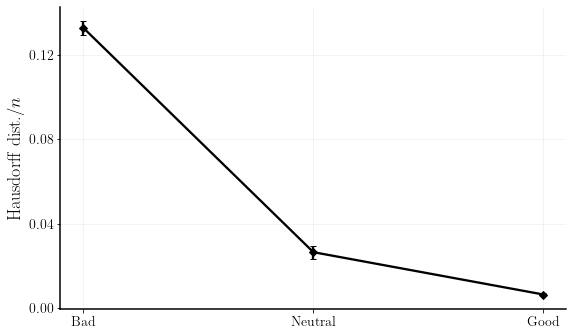

Exact prior for a randomly selected change point; panels: Bad, Neutral, Good. Dashed lines mark truth.


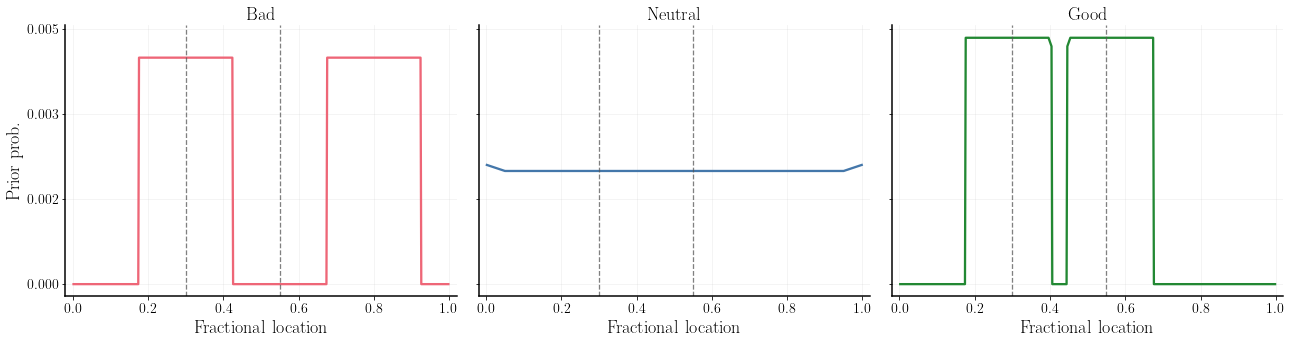

Exact joint prior over configurations (x: first change, y: second); panels: Bad, Neutral, Good.


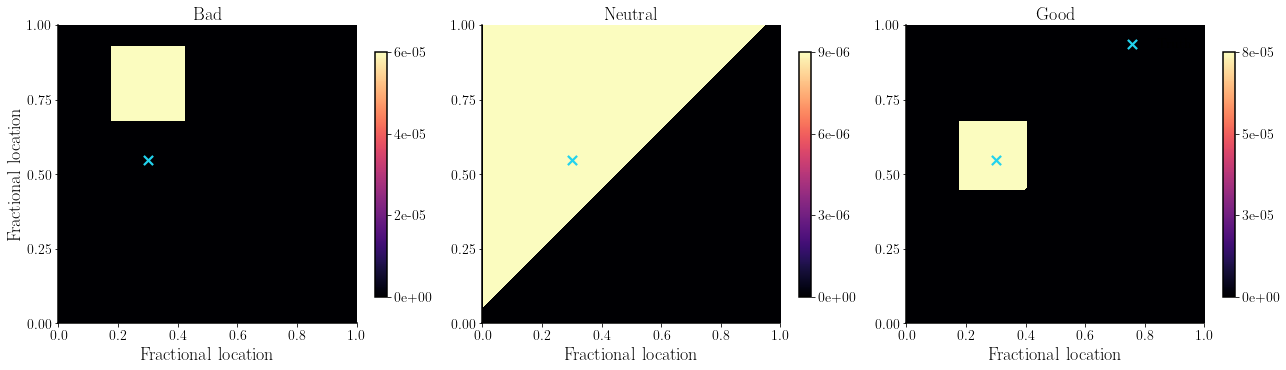

Signal-occupancy marginals derived from the joint priors; panels: Bad, Neutral, Good.


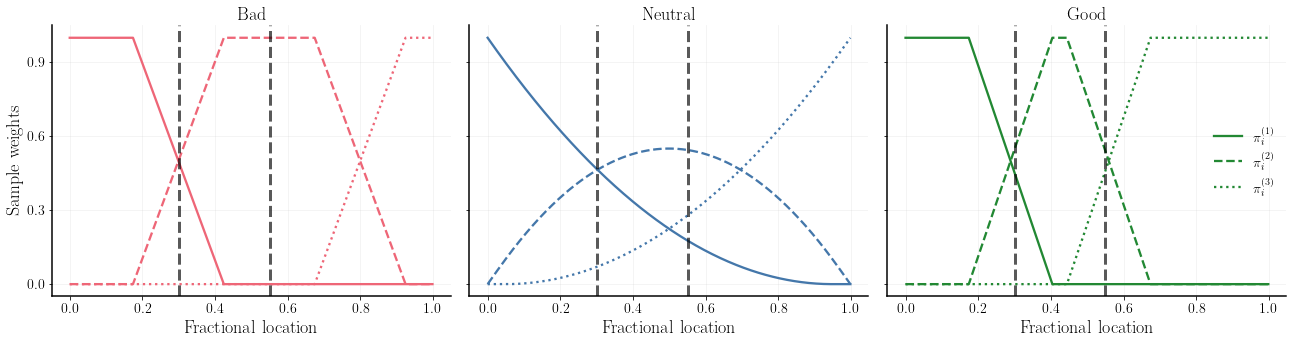

Conditional localization across paired trials (boxplots and faint jittered trial points).


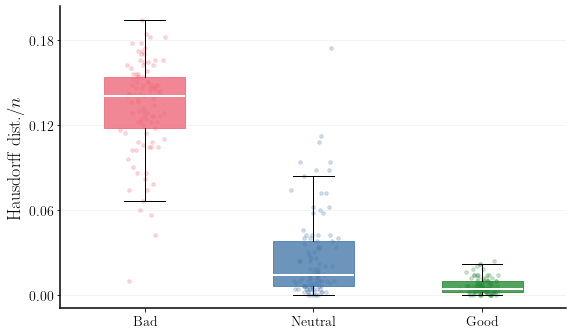

Estimated change-point locations; panels: Bad, Neutral, Good. Dashed lines mark truth.


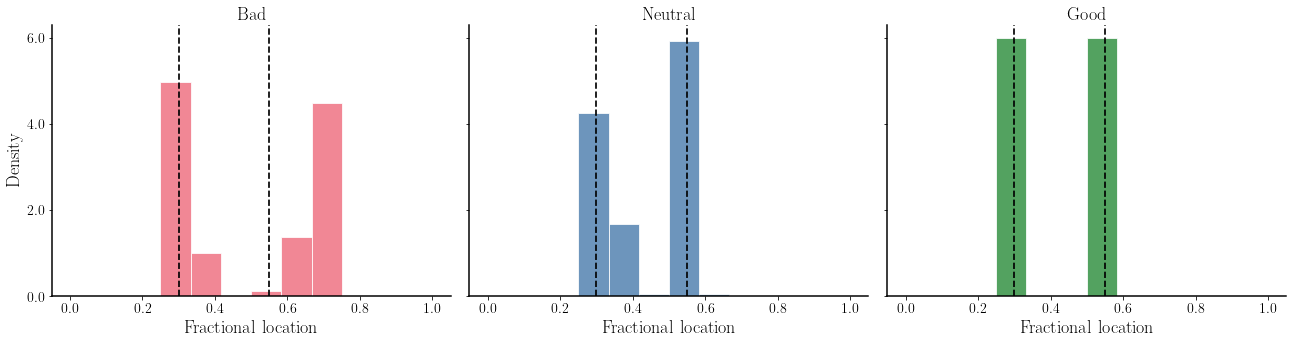

Ordered estimated change-point locations; left: first, right: second.


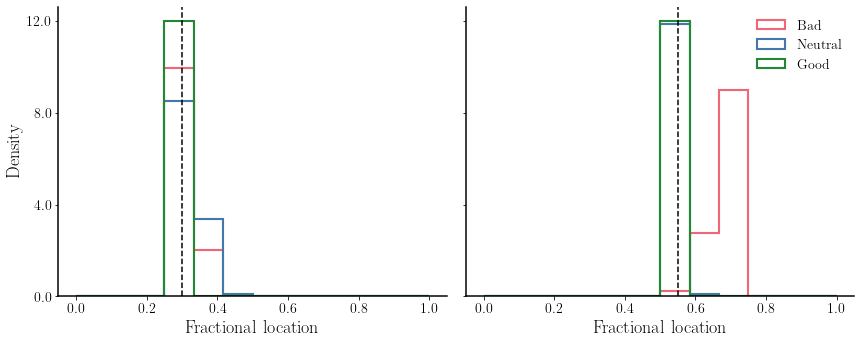

In [1]:

import pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.switch_backend("module://matplotlib_inline.backend_inline")
plt.rcParams.update({
    "font.family": "serif", "font.size": 14, "axes.labelsize": 18,
    "axes.linewidth": 1.5, "axes.titlesize": 18, "legend.fontsize": 14,
    "xtick.labelsize": 14, "ytick.labelsize": 14,
    "font.serif": ["Computer Modern Roman", "Times New Roman", "DejaVu Serif"],
    "text.usetex": True,
    "lines.linewidth": 3.0, "lines.markersize": 8,
    "figure.dpi": 72, "savefig.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False,
})
SMOKE_MODE = __import__("os").environ.get("WERM_SMOKE") == "1"

def series(trials, key, metric):
    return np.array([row[key][metric] for row in trials], dtype=float)

def mean_se(values):
    finite = np.isfinite(values)
    count = finite.sum(axis=0)
    mean = np.divide(np.nansum(values, axis=0), count,
                     out=np.full(values.shape[1], np.nan), where=count > 0)
    centered = np.where(finite, values - mean, 0)
    sd = np.sqrt(np.divide((centered**2).sum(axis=0), np.maximum(count-1, 1)))
    se = np.divide(sd, np.sqrt(count), out=np.zeros_like(sd), where=count > 0)
    return mean, se

def line_panel(ax, x, values, ylabel, color="black", theory=None):
    mean, se = mean_se(values)
    ax.errorbar(x, mean, yerr=se, color=color, marker="D", linestyle="-",
                linewidth=2.3, markersize=5, capsize=3, label="WERM")
    if theory is not None:
        ax.plot(x, theory, marker="o", linestyle="--", color="#AA3377",
                linewidth=1.7, markersize=4, label="Population")
        ax.legend(frameon=False)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=.18)

def jitter_boxes(ax, grouped, labels, ylabel, colors):
    rng = np.random.default_rng(2901)
    positions = np.arange(1, len(grouped)+1)
    clean = [np.asarray(g)[np.isfinite(g)] for g in grouped]
    for k, values in enumerate(clean):
        if len(values):
            ax.scatter(rng.normal(positions[k], .055, len(values)), values,
                       s=13, alpha=.23, color=colors[k], zorder=2)
    bp = ax.boxplot([g if len(g) else [np.nan] for g in clean],
                    positions=positions, widths=.48, patch_artist=True,
                    showfliers=False, medianprops=dict(color="white", linewidth=2))
    for patch, color in zip(bp["boxes"], colors):
        patch.set(facecolor=color, edgecolor=color, alpha=.78)
    ax.set_xticks(positions, labels)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=.18)


from matplotlib.ticker import MaxNLocator, FormatStrFormatter
ARTIFACT = Path("results") / ("E_PRIOR_jointconfigs_actualgap_100paired_seed20260916_smoke.pkl" if SMOKE_MODE
                              else "E_PRIOR_jointconfigs_actualgap_100paired_seed20260916.pkl")
with ARTIFACT.open("rb") as handle:
    payload = pickle.load(handle)
trials, params = payload["trials"], payload["params"]
phi, configs = payload["marginals"], payload["configs"]
names = ["Bad", "Neutral", "Good"]
colors = {"Neutral":"#4477AA", "Good":"#228833", "Bad":"#EE6677"}
true_cp, n = np.asarray(params["true_cp"]), params["N"]

def pooled_change_point_prior_mass(configurations, n):
    """Exact PMF of a uniformly selected change point from each configuration.

    Each configuration contributes half its mass at each of its two changes.
    The x coordinates are i/n, but the y values are probabilities summing to 1.
    """
    configurations = np.asarray(configurations, dtype=int)
    counts = np.bincount(configurations.reshape(-1), minlength=n)
    mass = counts.astype(float) / (2 * len(configurations))
    return mass, np.arange(n) / n

def exact_joint_prior_mass(configurations, n):
    """Exact joint configuration mass on the observed n-by-n index grid."""
    configurations = np.asarray(configurations, dtype=int)
    mass = np.zeros((n, n), dtype=float)
    np.add.at(mass, (configurations[:, 0], configurations[:, 1]),
              1.0 / len(configurations))
    return mass

print(f"E-PRIOR: {len(trials)} paired trials, n={n}, p={params['P']}; artifact: {ARTIFACT}")
print("Prior | configurations | mean selected changes | mean / median conditional Hausdorff")
for name in names:
    rows = [row[name] for row in trials]
    avg = lambda key: np.nanmean([r[key] for r in rows])
    conditional = np.asarray([r["conditional_haus"] for r in rows], dtype=float)
    print(f"{name} | {len(configs[name]):,} | {avg('count'):.2f} | "
          f"{np.nanmean(conditional):.3f} / {np.nanmedian(conditional):.3f}")

plt.rcParams.update({"font.size": 14, "xtick.labelsize": 14,
                     "ytick.labelsize": 14, "legend.fontsize": 14})
print("Conditional localization by prior (Bad, Neutral, Good); mean ± SE.")
fig, ax = plt.subplots(figsize=(8, 4.7))
values = np.column_stack([series(trials, name, "conditional_haus") for name in names])
mean, se = mean_se(values)
ax.errorbar(range(3), mean, yerr=se, color="black", marker="D",
            linestyle="-", linewidth=2.3, markersize=5, capsize=3)
ax.set_xticks(range(3), names)
ax.set_ylabel(r"Hausdorff dist./$n$")
ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax.grid(alpha=.18)
fig.tight_layout(pad=.6)
plt.show()

# Distribution of A change point: choose one of the two uniformly within each
# sampled configuration. This pools ordered positions without treating either
# one as special. Use exact probability mass per index, not a scaled density.
print("Exact prior for a randomly selected change point; panels: Bad, Neutral, Good. Dashed lines mark truth.")
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for ax, name in zip(axes, names):
    mass, x_grid = pooled_change_point_prior_mass(configs[name], n)
    ax.plot(x_grid[1:], mass[1:], color=colors[name], linewidth=2.3)
    for cp in true_cp:
        ax.axvline(cp / n, color="#555555", linestyle="--",
                   linewidth=1.3, alpha=.75)
    ax.set_title(name)
    ax.set_xlabel("Fractional location")
    ax.set_xlim(-.02, 1.02)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.3f"))
    ax.grid(alpha=.16)
axes[0].set_ylabel("Prior prob.")
fig.tight_layout(pad=.6, w_pad=1.1)
plt.show()

# A second view keeps the joint dependence that a pair of 1-D curves hides.
# Each pixel is one exact configuration (cp1, cp2), not a coarse histogram bin.
print("Exact joint prior over configurations (x: first change, y: second); panels: Bad, Neutral, Good.")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.0))
for ax, name in zip(axes, names):
    mass = exact_joint_prior_mass(configs[name], n)
    mesh = ax.imshow(mass.T, origin="lower", interpolation="none",
                     extent=(0, 1, 0, 1), cmap="magma", aspect="equal")
    ax.scatter([true_cp[0] / n], [true_cp[1] / n], marker="x",
               color="#22D3EE", s=85, linewidth=2.2, label="Truth")
    ax.set_title(name)
    ax.set_xlabel("Fractional location")
    if ax is axes[0]: ax.set_ylabel("Fractional location")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    fig.colorbar(mesh, ax=ax, shrink=.75, format="%.0e",
                 ticks=np.linspace(0, mass.max(), 4))
axes[-1].legend(frameon=False)
fig.tight_layout(pad=.5, w_pad=.7)
plt.show()

# Marginals are derived from the joint prior, not guessed as independent windows.
print("Signal-occupancy marginals derived from the joint priors; panels: Bad, Neutral, Good.")
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
line_styles = ("-", "--", ":")
for ax, name in zip(axes, names):
    for l in range(3):
        ax.plot(np.arange(n)/n, phi[name][l], linewidth=2.3,
                color=colors[name], linestyle=line_styles[l],
                label=rf"$\pi_{{i}}^{{({l+1})}}$")
    for cp in true_cp/n: ax.axvline(cp, color="black", linestyle="--", alpha=.65)
    ax.set_title(name)
    ax.set_xlabel("Fractional location")
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
    ax.grid(alpha=.16)
axes[0].set_ylabel("Sample weights")
axes[-1].legend(frameon=False, loc="center right")
fig.tight_layout(pad=.6, w_pad=1.1)
plt.show()

print("Conditional localization across paired trials (boxplots and faint jittered trial points).")
fig, ax = plt.subplots(figsize=(8, 4.7))
jitter_boxes(ax, [series(trials, name, "conditional_haus") for name in names],
             names, r"Hausdorff dist./$n$", [colors[name] for name in names])
ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
fig.tight_layout(pad=.6)
plt.show()

print("Estimated change-point locations; panels: Bad, Neutral, Good. Dashed lines mark truth.")
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for ax, name in zip(axes, names):
    cps = np.concatenate([row[name]["cp"] / n for row in trials])
    ax.hist(cps, bins=12, range=(0, 1), density=True, color=colors[name],
            alpha=.78, edgecolor="white", label="Empirical")
    for cp in true_cp/n: ax.axvline(cp, color="black", linestyle="--", linewidth=1.7)
    ax.set_title(name)
    ax.set_xlabel("Fractional location")
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
axes[0].set_ylabel("Density")
fig.tight_layout(pad=.6, w_pad=1.1)
plt.show()

print("Ordered estimated change-point locations; left: first, right: second.")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, coordinate in zip(axes, (0, 1)):
    for name in names:
        values = np.array([row[name]["cp"][coordinate] / n for row in trials])
        ax.hist(values, bins=12, range=(0, 1), density=True, histtype="step",
                linewidth=2.1, color=colors[name], label=name)
    ax.axvline(true_cp[coordinate]/n, color="black", linestyle="--", linewidth=1.5)
    ax.set_xlabel("Fractional location")
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
axes[0].set_ylabel("Density")
axes[-1].legend(frameon=False)
fig.tight_layout(pad=.6, w_pad=1.1)
plt.show()


## Updated consistent plots

Plotting reference: **Canonical M1 tighter-layout plots (alpha = 0.3)** in `M1_upsample_final.ipynb`. Error-bar plots use its 5 by 4 inch canvas, 18 pt axis labels and 14 pt ticks; among Hausdorff, count and runtime comparisons, only Runtime displays a legend. These cells load saved results only; the original experiment and plotting cells above are unchanged. Run the setup below, then the desired plotting cell. PDFs and PNGs are saved under `results/consistent_plots_20261102/E_PRIOR/`.

Line summaries retain their original statistic (quartile-distance bars, or mean ± SE where stated); boxplots use 1.5-IQR whiskers and faint deterministic trial jitter. Histograms follow canonical M1: 12 data-range bins, five-fold bandwidth-selected Gaussian KDE, grey overlay, truth-position ticks, and density range 0–18. These histogram display choices can differ from the older plots; the samples do not change. Empty estimates are omitted from conditional localization and pooled location densities, not assigned zero error. Histograms retain every selected setting and method in one grid, with no three-row or three-column cap: 2.5 inches per column and 2.2 inches per row, matching the reference. Other diagnostic plots retain their compact presentation.

In [1]:
"""Approved publication style; also embedded verbatim in final notebook cells.

Only plotting helpers live here. All data choices and plot calls are visible in
the notebook cells. No fitting, simulation, CV for estimators, or job submission.
Histogram KDE bandwidth CV is the canonical M1 visualization procedure.
"""
from pathlib import Path
import hashlib
import json
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FuncFormatter, NullFormatter
from matplotlib.patches import Patch
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV
from IPython.display import display, Image

PAPER_WIDTH = 427.64493 / 72.27
PANEL_WIDTH = .49 * PAPER_WIDTH
SCALE = 10.5 / 18
PAPER_STYLE = {
    'text.usetex': True, 'font.family': 'serif',
    'font.serif': ['Computer Modern Roman'], 'font.size': 8.5,
    'axes.labelsize': 10.5, 'axes.titlesize': 10.5,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 8,
    'axes.linewidth': .85, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'xtick.major.width': .85, 'ytick.major.width': .85,
    'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
    'savefig.bbox': None, 'figure.dpi': 120, 'savefig.dpi': 180,
    'figure.autolayout': False, 'figure.constrained_layout.use': False,
    'legend.frameon': False, 'axes.formatter.useoffset': False,
    'text.latex.preamble': '', 'figure.facecolor': 'white', 'axes.facecolor': 'white',
}

# Reference: M1_upsample_final, "Canonical M1 tighter-layout plots (alpha=0.3)".
# Keep this separate from the compact style used for unrelated diagnostic plots.
CANONICAL_STYLE = {
    **PAPER_STYLE,
    'font.size': 14, 'axes.labelsize': 18, 'axes.titlesize': 18,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14,
    'axes.linewidth': 1.5, 'xtick.major.width': 1.5, 'ytick.major.width': 1.5,
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'legend.frameon': True, 'legend.fancybox': True,
    'legend.edgecolor': 'black', 'legend.framealpha': .95,
    'lines.linewidth': 4, 'lines.markersize': 8,
    'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.pad_inches': .1,
}

METHODS = {
    'McScan': ('McScan', '#AA3377', 'o', '--'),
    'MOSEG': ('MOSEG', '#228833', 's', '-.'),
    'DCDP': ('DCDP', '#EE6677', 'X', '--'),
    'DPDU': ('DPDU', '#4477AA', 'P', ':'),
    'charcoal': ('charcoal', '#336677', 'v', '-.'),
    'GLMBSA-CV': ('GLMBSA', '#E69F00', 'p', ':'),
    'WERM-unp': (r'\textbf{WERM}', 'black', 'D', '-'),
    'WERM-unp-10fold': (r'\textbf{WERM}', 'black', 'D', '-'),
    'WERM-L1-jointCV': (r'\textbf{WERM+L1}', 'black', 'D', '-'),
    'WERM-L1-fullCV-2fold': (r'\textbf{WERM+L1}', 'black', 'D', '-'),
}
SOURCE_HASHES, FIGURE_AUDIT = {}, []
KDE_CACHE = {}

def load_saved(filename):
    path = Path(filename)
    raw = path.read_bytes()  # fail explicitly if a result is missing; no dummy data
    SOURCE_HASHES[str(path)] = hashlib.sha256(raw).hexdigest()
    return pickle.loads(raw)

def clean(values):
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]

def paper_panel(full=False, height=2.05):
    fig, ax = plt.subplots(figsize=(PAPER_WIDTH if full else PANEL_WIDTH, height))
    fig.subplots_adjust(left=.11 if full else .19, right=.98, bottom=.23, top=.97)
    ax.yaxis.set_major_locator(MaxNLocator(4))
    return fig, ax

def export_plot(fig, name, description=''):
    """Export PDF + embedded PNG, retaining canonical geometry and input hashes."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    canonical = getattr(fig, '_canonical_m1', False)
    bounds = fig.get_tightbbox(renderer).padded(.1) if canonical else fig.bbox_inches
    pixels = bounds.transformed(fig.dpi_scale_trans)
    for ax in fig.axes:
        if not ax.get_visible():
            continue
        bbox = ax.get_tightbbox(renderer)
        if bbox is not None:
            assert bbox.x0 >= pixels.x0-2 and bbox.y0 >= pixels.y0-2, (name, 'left/bottom clipping', bbox)
            assert bbox.x1 <= pixels.x1+2 and bbox.y1 <= pixels.y1+2, (name, 'right/top clipping', bbox)
    for text in fig.texts:
        bbox = text.get_window_extent(renderer)
        assert bbox.x0 >= pixels.x0-2 and bbox.y0 >= pixels.y0-2 and bbox.x1 <= pixels.x1+2 and bbox.y1 <= pixels.y1+2, (name, 'figure text clipping')
    fig.savefig(OUTPUT_DIR / f'{name}.pdf', bbox_inches=bounds)
    fig.savefig(OUTPUT_DIR / f'{name}.png', bbox_inches=bounds)
    FIGURE_AUDIT.append(dict(name=name, description=description,
        size_inches=[bounds.width, bounds.height],
        canvas_inches=fig.get_size_inches().tolist(),
        canonical_m1=canonical,
        legends=sum(a.get_legend() is not None for a in fig.axes)+len(fig.legends),
        axes=[dict(bounds=list(a.get_position().bounds), xlabel=a.get_xlabel(),
                   ylabel=a.get_ylabel(), title=a.get_title(), ylim=list(a.get_ylim())) for a in fig.axes]))
    print(description or name)
    display(Image(filename=str(OUTPUT_DIR / f'{name}.png')))
    plt.close(fig)
    (OUTPUT_DIR/'manifest.json').write_text(json.dumps(dict(
        style=PAPER_STYLE, sources=SOURCE_HASHES, figures=FIGURE_AUDIT), indent=2))

def verify_sources():
    for path, digest in SOURCE_HASHES.items():
        assert hashlib.sha256(Path(path).read_bytes()).hexdigest() == digest, path
    print(f'Exported {len(FIGURE_AUDIT)} figures to {OUTPUT_DIR}; saved inputs unchanged.')

def error_series(ax, x, groups, label, color='black', marker='D', ls='-', error='quartile', scale=SCALE):
    xplot, means, low, high = [], [], [], []
    for xx, group in zip(x, groups):
        v = clean(group)
        if not len(v):
            continue
        mean = v.mean()
        if error == 'se':
            lo = hi = v.std(ddof=1)/np.sqrt(len(v)) if len(v)>1 else 0
        else:
            q25, q75 = np.percentile(v, [25,75])
            lo, hi = abs(mean-q25), abs(q75-mean)
        xplot.append(xx); means.append(mean); low.append(lo); high.append(hi)
    ax.errorbar(xplot,means,yerr=[low,high],label=label,color=color,marker=marker,ls=ls,
        linewidth=3.5*scale,markersize=8*scale,capsize=4*scale,capthick=2*scale,
        markeredgewidth=2*scale,markeredgecolor='white',alpha=.8)

def box_group(ax, values, position, color, rng, width=.65, jitter=.19):
    v=clean(values)
    if not len(v):
        return
    bp=ax.boxplot([v],positions=[position],widths=width,patch_artist=True,
        showfliers=False,whis=1.5,autorange=True,manage_ticks=False,
        medianprops=dict(color='black',linewidth=2.3*SCALE,zorder=6),
        boxprops=dict(color='black',linewidth=1.35*SCALE),
        whiskerprops=dict(color='black',linewidth=1.25*SCALE),
        capprops=dict(color='black',linewidth=1.25*SCALE))
    bp['boxes'][0].set(facecolor=color,alpha=.28)
    ax.scatter(position+rng.uniform(-jitter,jitter,len(v)),v,s=3,alpha=.12,
               color=color,linewidths=0,zorder=4)
    q25,med,q75=np.percentile(v,[25,50,75])
    if np.isclose(q25,q75,rtol=1e-10,atol=1e-12*max(1.,np.max(np.abs(v)))):
        ax.plot([position-.43*width,position+.43*width],[med,med],
                color='black',lw=3.4*SCALE,zorder=7)

def histogram_grid(groups, titles, colors, truth, name, row_labels=None,
                   panel_titles=None, density_limit=18, density_label_x=.07):
    """Canonical M1 histogram grid with every selected row and method column.

    groups[row][column] contains pooled fractional change-point estimates.
    Uses the exact M1 12-bin/data-range and five-fold Gaussian-KDE setup.
    The fixed canonical density range is retained; clipped peaks are reported.
    """
    with plt.rc_context(CANONICAL_STYLE):
        rows, cols=len(groups),len(titles)
        assert rows>=1 and cols>=1 and all(len(g)==cols for g in groups)
        fig, axes=plt.subplots(rows,cols,figsize=(2.5*cols,2.2*rows),
            sharex=True,sharey=True,squeeze=False,
            gridspec_kw=dict(wspace=.05,hspace=.55 if panel_titles and rows>1 else .08))
        fig._canonical_m1 = True
        peak=0.
        for row in range(rows):
            for col in range(cols):
                ax=axes[row,col]; values=clean(groups[row][col])
                assert np.all((values>=0)&(values<=1)), 'Histogram expects fractional locations'
                if len(values):
                    hist, edges, _=ax.hist(values,bins=12,alpha=.8,color=colors[col],
                        density=True,edgecolor='white',linewidth=1.0)
                    assert np.isclose(np.sum(hist*np.diff(edges)),1)
                    peak=max(peak,float(hist.max()))
                    if len(values)>6:
                        key=hashlib.sha256(values.tobytes()).hexdigest()
                        if key not in KDE_CACHE:
                            cv=GridSearchCV(KernelDensity(kernel='gaussian'),
                                {'bandwidth':np.logspace(-2,0,50)},cv=5,n_jobs=1)
                            cv.fit(values.reshape(-1,1))
                            x=np.linspace(0,1,200)
                            KDE_CACHE[key]=(x,np.exp(cv.best_estimator_.score_samples(x.reshape(-1,1))))
                        x,y=KDE_CACHE[key]
                        ax.plot(x,y,color='#555555',lw=1.0,ls='-',alpha=.8,zorder=2)
                        ax.fill_between(x,y,color='#999999',alpha=.2,zorder=1)
                        peak=max(peak,float(y.max()))
                else:
                    ax.text(.5,.5,r'\textit{N/A}',transform=ax.transAxes,
                        ha='center',va='center',fontsize=12,alpha=.7)
                for cp in truth:
                    ax.axvline(cp,color='black',ls='--',lw=2,alpha=.9,zorder=10)
                ax.set(xlim=(0,1),ylim=(0,density_limit))
                ax.set_xticks(truth,[f'${cp:.2f}$' for cp in truth])
                ax.set_yticks([0,8,16] if density_limit==18 else [0,density_limit/2,density_limit])
                ax.tick_params(width=1,length=4,labelsize=14)
                for spine in ('left','bottom'):ax.spines[spine].set_linewidth(1)
                if row==0 or panel_titles:
                    ax.set_title(panel_titles[row][col] if panel_titles else titles[col],
                                 fontsize=18,pad=10)
                if col==cols-1 and row_labels:
                    ax.text(1.05,.5,row_labels[row],transform=ax.transAxes,rotation=90,
                        va='center',ha='left',fontsize=18)
        fig.text(.5,.01,'Fractional location',ha='center',va='bottom',fontsize=18)
        fig.text(density_label_x,.5,'Density',va='center',rotation='vertical',fontsize=18)
        fig.tight_layout(rect=[.03,.05,.96,.96])
        # Keep the shared x label clear of tick labels in shorter grids.
        if rows==1:fig.subplots_adjust(bottom=.28,top=.78)
        elif rows==2:fig.subplots_adjust(bottom=.16)
        if peak>density_limit:
            print(f'{name}: maximum density {peak:.2f}; canonical display limit {density_limit} (peaks above this are clipped).')
        export_plot(fig,name,'Change-point location histograms: canonical M1 bins, KDE, ticks and layout.')

def comparison_plots(filename, prefix, methods, min_x=None, m3=False,
                     histogram_stride=3, metrics=('haus','size','runtime'), histograms=True):
    payload=load_saved(filename); results,params=payload['results'],payload['params']
    raw_x=np.asarray(params['kappa_list'] if m3 else params['delta_list'])
    keep=np.flatnonzero(raw_x>=min_x) if min_x is not None else np.arange(len(raw_x))
    x=raw_x[keep]**2 if m3 else raw_x[keep]
    xlabel=r'$\kappa^2$' if m3 else r'$\delta=n/p$'
    truth=np.asarray(params['fractional_chgpt_locations'])
    values={}
    for method in methods:
        sizes=np.asarray(results['size_'+method],float)[keep]
        assert sizes.shape[1]==params['num_trials']
        for metric in metrics:
            v=(np.abs(sizes-len(truth)) if metric=='size_error' else
               np.asarray(results[metric+'_'+method],float)[keep].copy())
            if metric=='haus':v=np.where(sizes>0,v,np.nan)
            if metric=='size_error':v=np.abs(sizes-len(truth))
            values[metric,method]=v
    for metric in metrics:
        ylabel={'haus':r'Hausdorff dist. / $n$','size':'No. change points',
                'runtime':'Runtime (s)','size_error':'Set size error'}[metric]
        for kind in ('line','box'):
            with plt.rc_context(CANONICAL_STYLE if kind=='line' else PAPER_STYLE):
                if kind=='line':
                    fig,ax=plt.subplots(figsize=(5.,4.))
                    fig._canonical_m1 = True
                else:
                    fig,ax=paper_panel()
                rng=np.random.default_rng(42)
                handles=[]
                for j,method in enumerate(methods):
                    label,color,marker,ls=METHODS[method];v=values[metric,method]
                    if kind=='line':
                        error_series(ax,x,v,label,color,marker,ls,scale=1)
                    else:
                        for k,g in enumerate(v):box_group(ax,g,k*(len(methods)+1)+j,color,rng)
                        handles.append(Patch(facecolor=color,alpha=.28,edgecolor='black',label=label))
                if kind=='line':
                    if m3:
                        # Preserve the canonical M3 logarithmic kappa-squared axis.
                        ax.set_xscale('log')
                        ax.set_xticks([10,100,1000],['10','100','1000'])
                        ax.xaxis.set_minor_formatter(NullFormatter())
                    else:
                        ax.set_xticks(x[::2],[f'{xx:g}' for xx in x[::2]])
                else:
                    ax.set_xticks(np.arange(len(x))[::2]*(len(methods)+1)+(len(methods)-1)/2,
                                  [f'{xx:.0f}' if m3 else f'{xx:g}' for xx in x[::2]])
                ax.set(xlabel=xlabel,ylabel=ylabel)
                if metric=='size':
                    ax.axhline(len(truth),color='gray',lw=2.5*(1 if kind=='line' else SCALE),alpha=.8,zorder=0)
                    ax.yaxis.set_major_locator(MaxNLocator(4,integer=True));ax.set_ylim(bottom=-.15)
                    if m3:
                        ax.set_ylim(0,params['L']);ax.set_yticks(np.arange(params['L']+1))
                elif metric=='size_error':ax.yaxis.set_major_locator(MaxNLocator(4,integer=True))
                elif metric=='runtime':ax.set_ylim(bottom=0)
                if metric == ('size' if m3 else 'runtime'):
                    ax.legend(handles=handles if kind=='box' else None,loc='best',
                              prop={'size':14 if kind=='line' else 8},
                              fancybox=True,framealpha=.4)
                if kind=='line':
                    ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
                    ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
                    for spine in ('left','bottom'):ax.spines[spine].set_linewidth(1.5)
                    fig.tight_layout()
                export_plot(fig,f'{prefix}_{metric}_{kind}',
                    f'{prefix}: {ylabel}; '+('mean and absolute distances to quartiles' if kind=='line' else 'boxplots with faint trial jitter'))
    if not histograms:return
    # Preserve all selected settings and methods in one canonical grid.
    row_idx=keep[::histogram_stride]
    keys=list(reversed(methods));groups=[]
    for index in row_idx:
        n=int(params['p']*(params['fixed_delta'] if m3 else raw_x[index]))
        group=[]
        for key in keys:
            parts=[np.asarray(cps).ravel() for i,cps in results['chgpts_'+key] if i==index]
            cp=np.concatenate(parts) if parts else np.array([])
            group.append(cp[cp!=-1]/n)
        groups.append(group)
    histogram_grid(groups,[METHODS[k][0] for k in keys],[METHODS[k][1] for k in keys],truth,
        f'{prefix}_hist',
        [rf'$\kappa^2={raw_x[i]**2:.0f}$' if m3 else rf'$\delta={raw_x[i]:g}$' for i in row_idx])


def simple_summary(groups, x, xlabel, ylabel, name, colors=None, error='quartile',
                   kind='box', labels=None, truth=None, title=None):
    with plt.rc_context(CANONICAL_STYLE if kind=='line' else PAPER_STYLE):
        canonical = kind=='line'
        fig,ax=plt.subplots(figsize=(5.,4.)) if canonical else paper_panel()
        fig._canonical_m1 = canonical
        colors=colors or ['black']*len(x)
        if kind=='line':error_series(ax,x,groups,'',error=error,scale=1)
        else:
            rng=np.random.default_rng(42)
            for xx,g,color in zip(x,groups,colors):box_group(ax,g,xx,color,rng,width=.55,jitter=.16)
        ax.set_xticks(x,labels or [str(xx) for xx in x])
        ax.set(xlabel=xlabel,ylabel=ylabel)
        if truth is not None:ax.axhline(truth,color='gray',lw=2.5*(1 if canonical else SCALE),alpha=.8,zorder=0)
        if title:
            fig.subplots_adjust(top=.86)
            ax.set_title(title,pad=4)
        if ylabel=='No. change points':ax.yaxis.set_major_locator(MaxNLocator(4,integer=True))
        if canonical:
            ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
            fig.tight_layout()
        export_plot(fig,name)

OUTPUT_DIR=Path('results/consistent_plots_20261102/E_PRIOR')


### Bad, neutral and good priors

Prior | mean Hausdorff / n | median Hausdorff / n
Bad 0.13278 0.14
Neutral 0.026500000000000003 0.014
Good 0.006440000000000001 0.004


prior_location_line


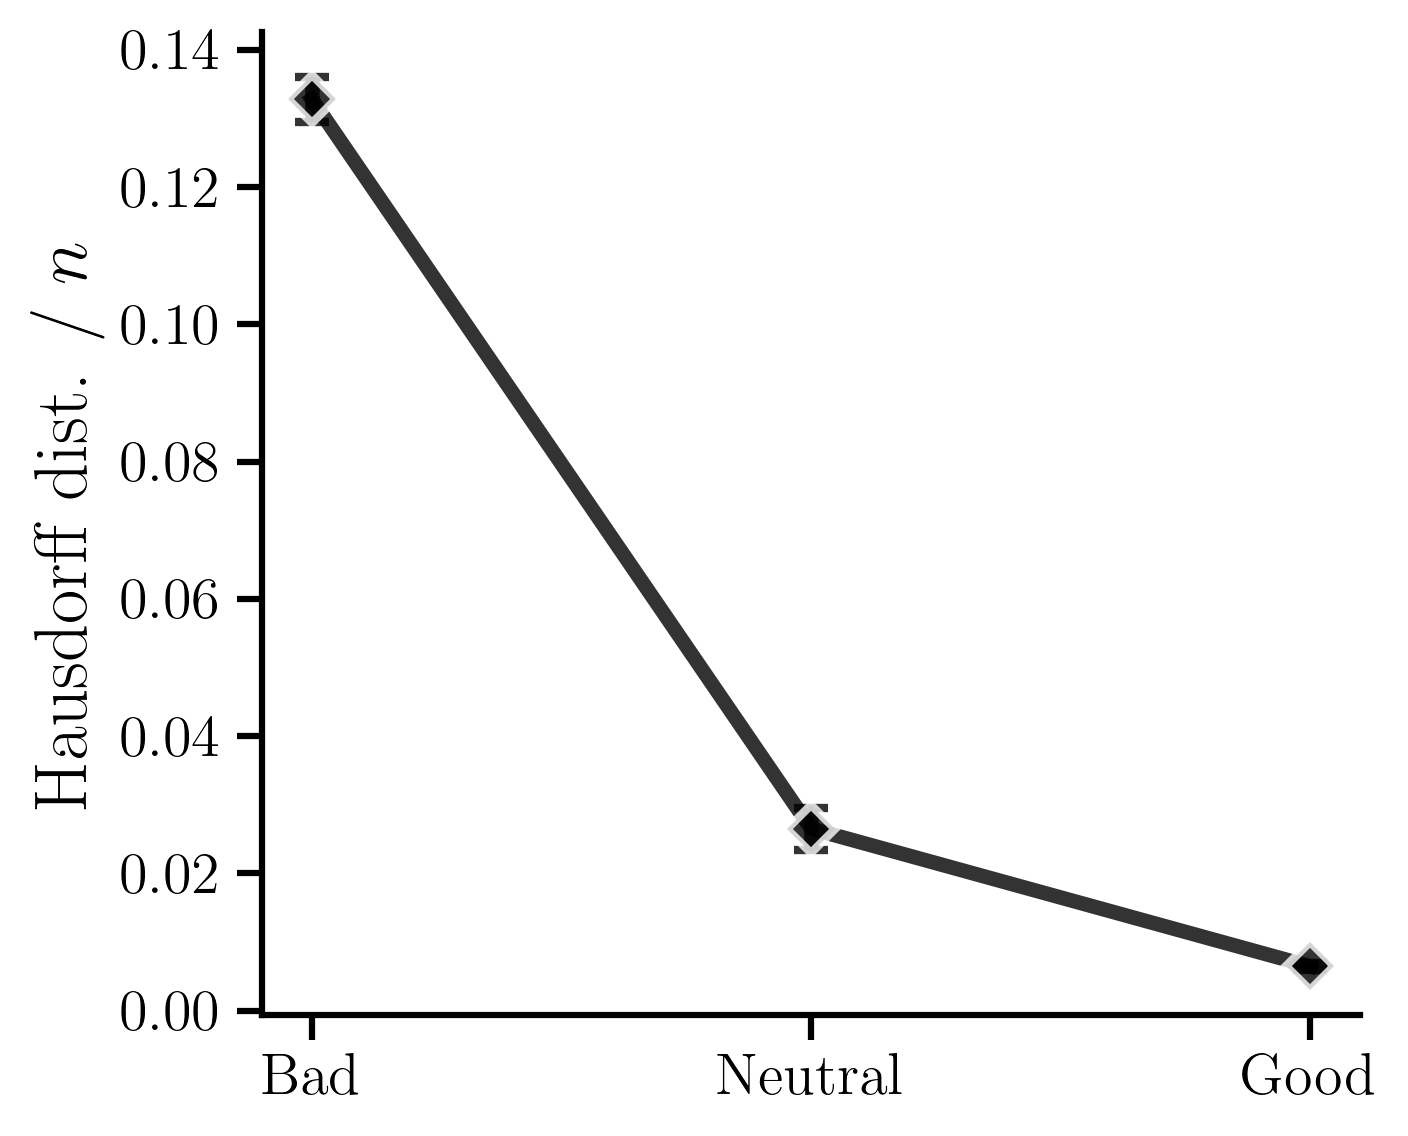

prior_location_box


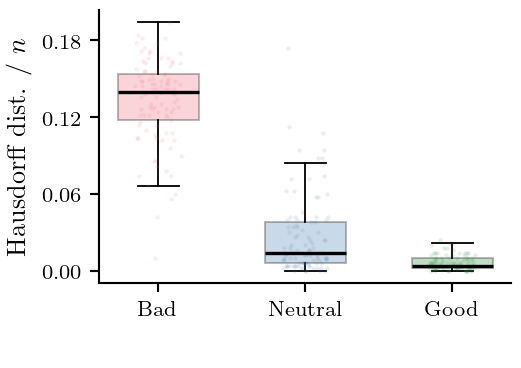

pooled_prior


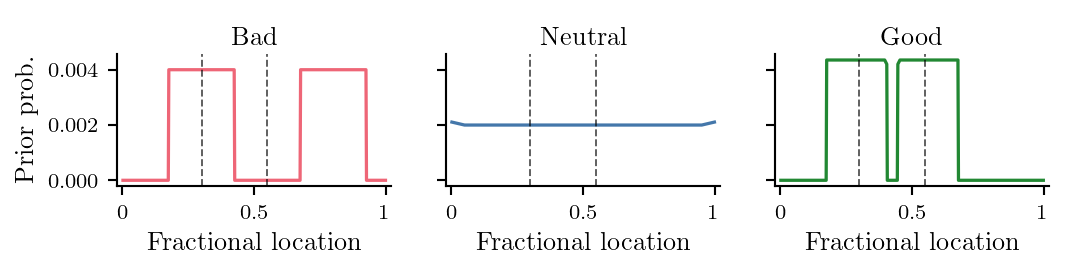

signal_marginals


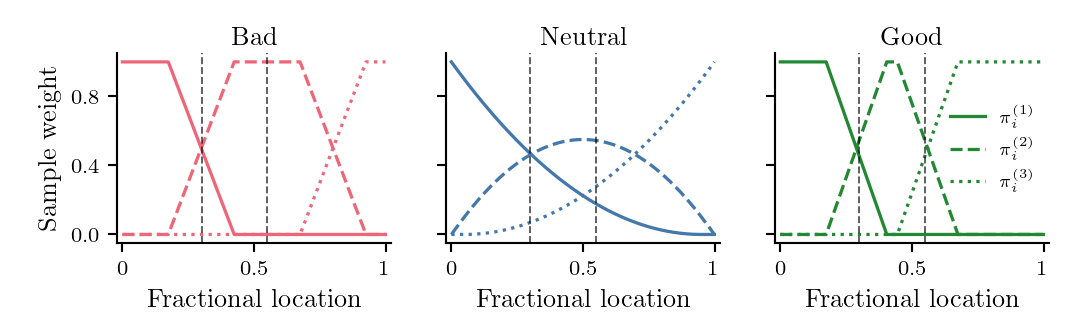

joint_configuration_priors


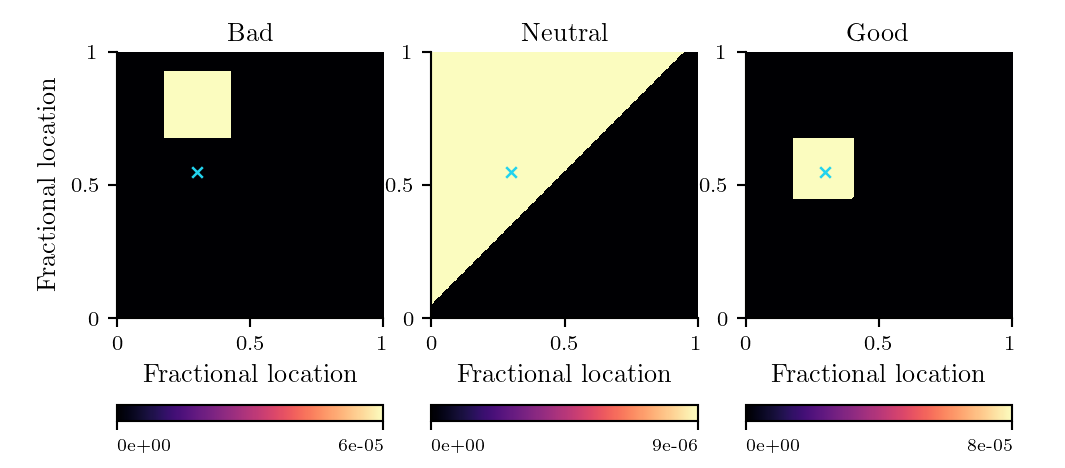

prior_estimated_locations: maximum density 19.58; canonical display limit 18 (peaks above this are clipped).
Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


/tmp/ipykernel_3360542/3149096911.py:209: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[.03,.05,.96,.96])


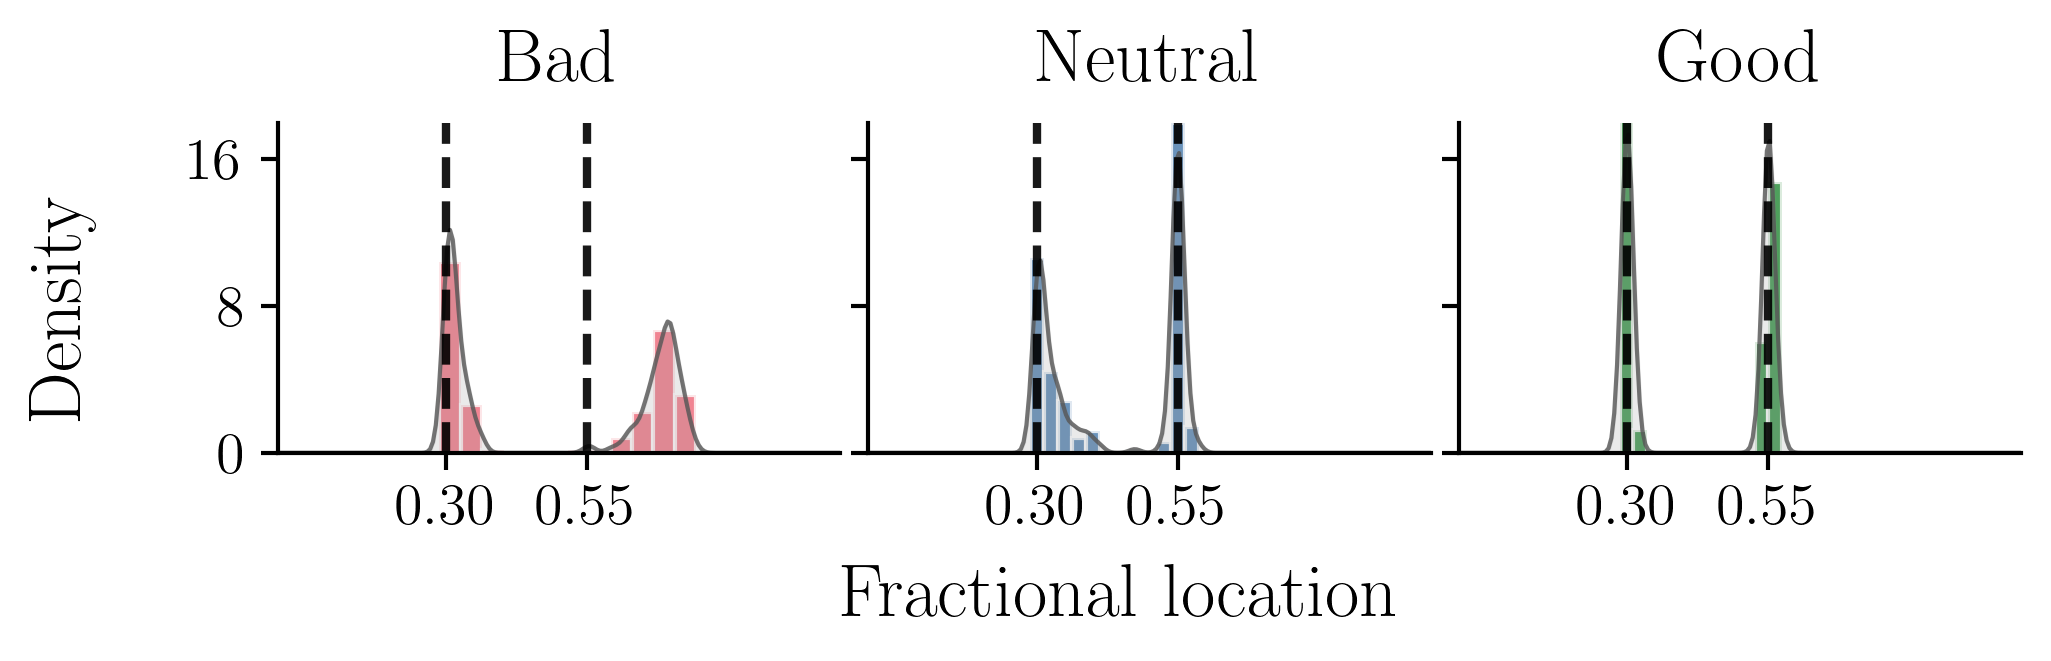

/tmp/ipykernel_3360542/3149096911.py:209: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[.03,.05,.96,.96])


prior_ordered_estimates: maximum density 148.24; canonical display limit 18 (peaks above this are clipped).


Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


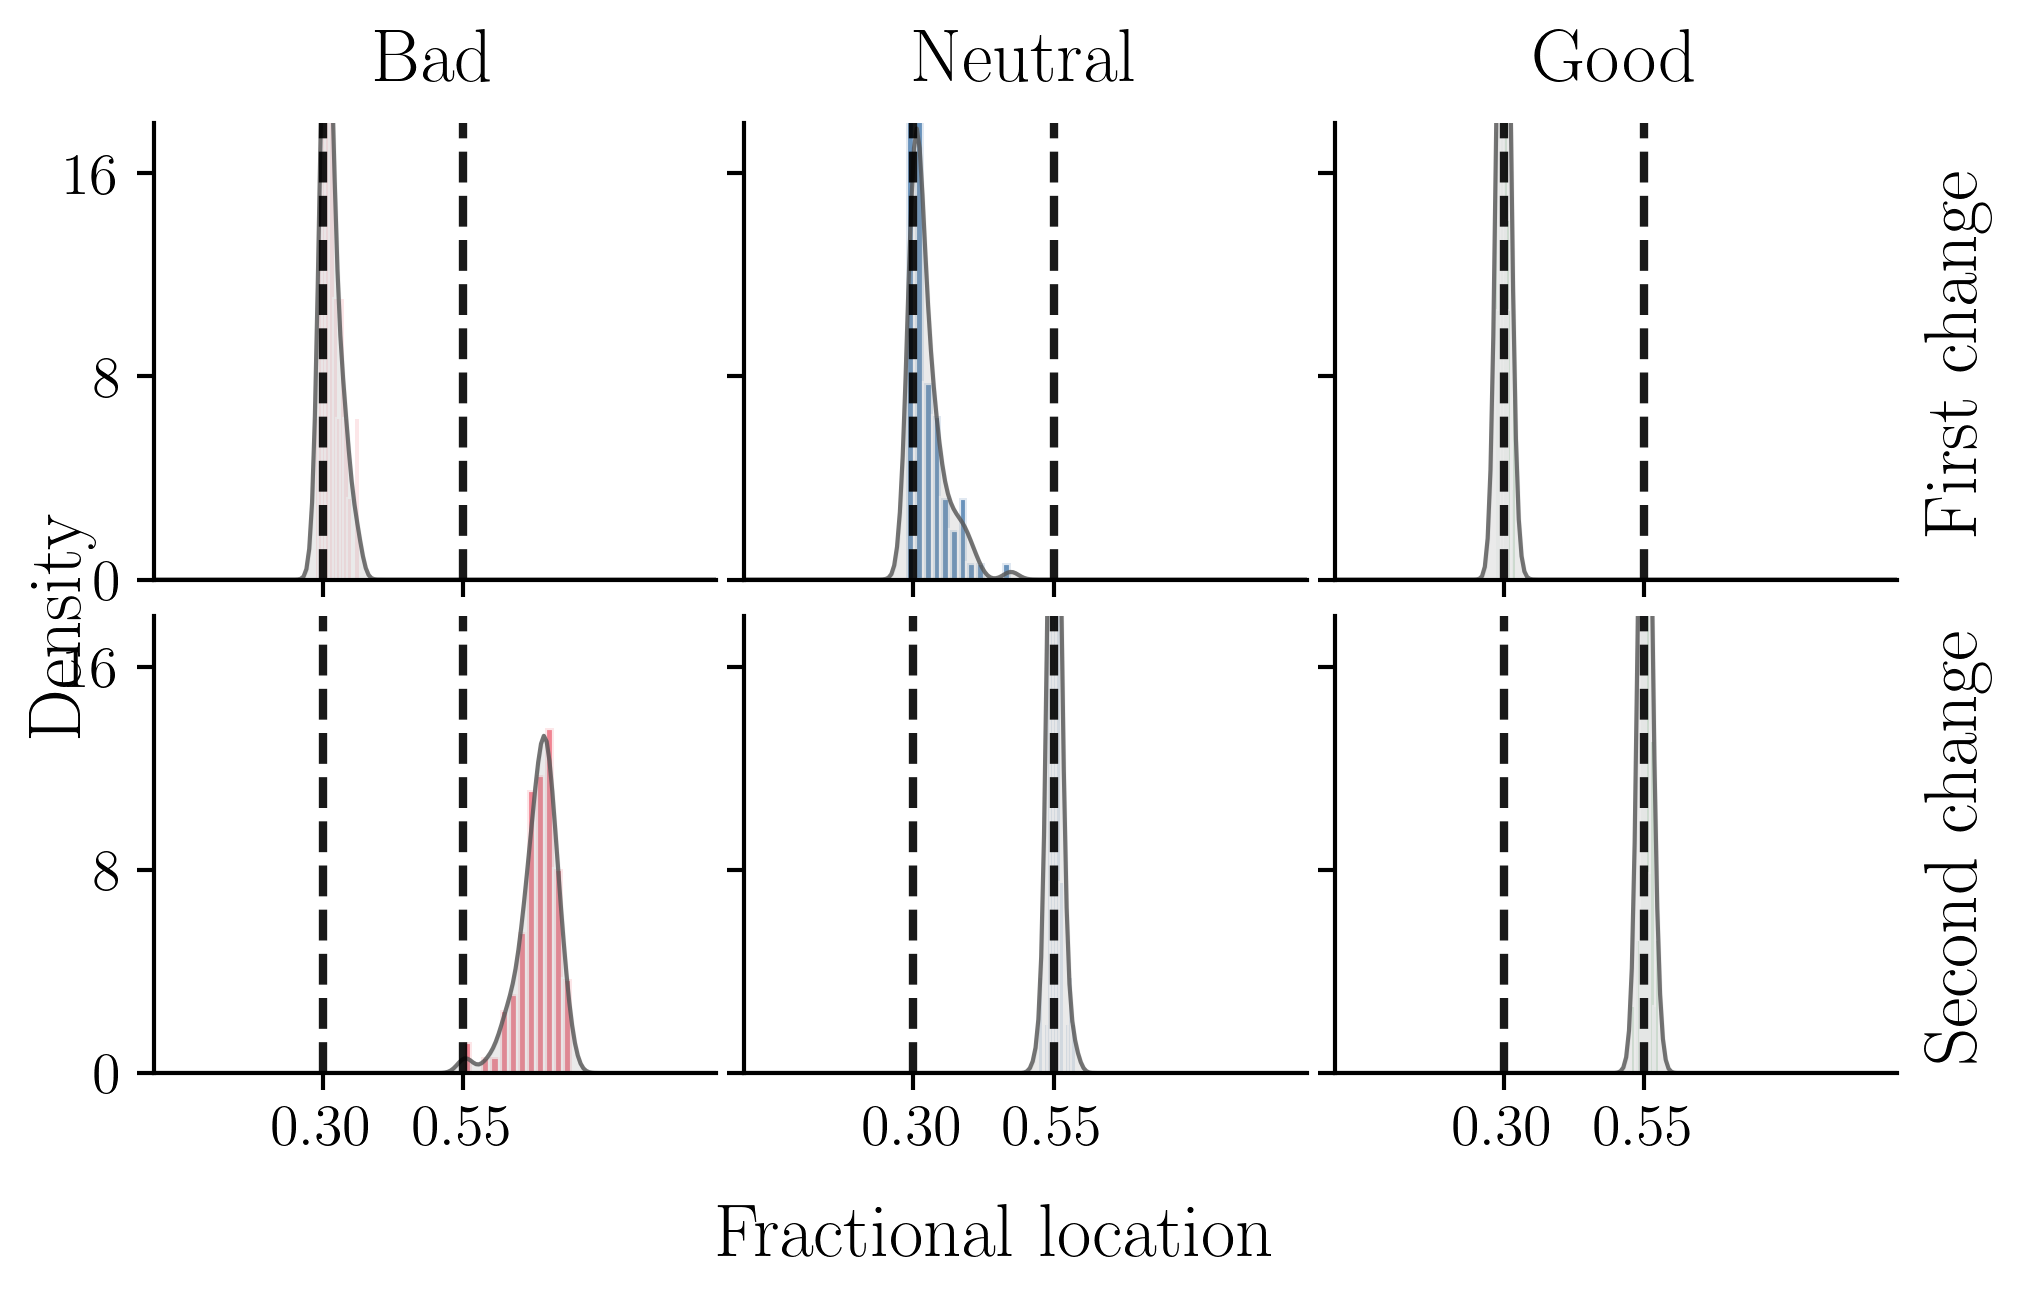

In [2]:
saved=load_saved('results/E_PRIOR_jointconfigs_actualgap_100paired_seed20260916.pkl')
trials,params=saved['trials'],saved['params'];n=params['N']
names=['Bad','Neutral','Good'];colors=['#EE6677','#4477AA','#228833']
truth=np.asarray(params['true_cp'])/n
groups=[[row[name]['conditional_haus'] for row in trials] for name in names]
print('Prior | mean Hausdorff / n | median Hausdorff / n')
for name,values in zip(names,groups):print(name,np.nanmean(values),np.nanmedian(values))
with plt.rc_context(PAPER_STYLE):
    simple_summary(groups,np.arange(3),'',r'Hausdorff dist. / $n$',
        'prior_location_line',kind='line',error='se',labels=names)
    simple_summary(groups,np.arange(3),'',r'Hausdorff dist. / $n$',
        'prior_location_box',colors=colors,labels=names)

    # Exact pooled prior masses and exact signal marginals: no resimulation or smoothing.
    for plot in ('pooled_prior','signal_marginals'):
        fig,axes=plt.subplots(1,3,figsize=(PAPER_WIDTH,1.85 if plot=='signal_marginals' else 1.5),sharey=True)
        fig.subplots_adjust(left=.11,right=.985,bottom=.27 if plot=='signal_marginals' else .31,
                            top=.84 if plot=='signal_marginals' else .80,wspace=.20)
        for ax,name,color in zip(axes,names,colors):
            if plot=='pooled_prior':
                configs=np.asarray(saved['configs'][name],int)
                mass=np.bincount(configs.ravel(),minlength=n)/(2*len(configs))
                assert np.isclose(mass.sum(),1)
                ax.plot(np.arange(1,n)/n,mass[1:],color=color,lw=1.3)
            else:
                marginal=np.asarray(saved['marginals'][name])
                np.testing.assert_allclose(marginal.sum(axis=0),1,atol=1e-8)
                for l,ls in enumerate(('-','--',':')):
                    ax.plot(np.arange(n)/n,marginal[l],color=color,ls=ls,lw=1.3,
                            label=rf'$\pi_i^{{({l+1})}}$')
            for cp in truth:ax.axvline(cp,color='black',ls='--',lw=.75,alpha=.65)
            ax.set(xlim=(-.02,1.02),xlabel='Fractional location')
            ax.set_title(name,pad=3);ax.set_xticks([0,.5,1],['0','0.5','1'])
            ax.yaxis.set_major_locator(MaxNLocator(3))
        axes[0].set_ylabel('Prior prob.' if plot=='pooled_prior' else 'Sample weight')
        if plot=='signal_marginals':axes[-1].legend(fontsize=7,loc='center right')
        export_plot(fig,plot)

    # Keep the exact joint-prior visualization; each pixel is a configuration.
    fig,axes=plt.subplots(1,3,figsize=(PAPER_WIDTH,2.6))
    for col,(ax,name) in enumerate(zip(axes,names)):
        left=.11+col*.295
        ax.set_position([left,.32,.25,.25*PAPER_WIDTH/2.6])
        configs=np.asarray(saved['configs'][name],int);mass=np.zeros((n,n))
        np.add.at(mass,(configs[:,0],configs[:,1]),1/len(configs))
        im=ax.imshow(mass.T,origin='lower',interpolation='none',extent=(0,1,0,1),cmap='magma',aspect='equal')
        ax.scatter(*truth,marker='x',color='#22D3EE',s=18,linewidth=1)
        ax.set_title(name,pad=4);ax.set_xlabel('Fractional location')
        ax.set_xticks([0,.5,1],['0','0.5','1']);ax.set_yticks([0,.5,1],['0','0.5','1'])
        cax=fig.add_axes([left,.10,.25,.035])
        cbar=fig.colorbar(im,cax=cax,orientation='horizontal',ticks=[0,mass.max()],format='%.0e')
        cbar.ax.tick_params(labelsize=7)
        cbar.ax.get_xticklabels()[0].set_ha('left')
        cbar.ax.get_xticklabels()[-1].set_ha('right')
    axes[0].set_ylabel('Fractional location')
    export_plot(fig,'joint_configuration_priors')

    pools=[np.concatenate([np.asarray(row[name]['cp'])/n for row in trials]) for name in names]
    histogram_grid([pools],names,colors,truth,'prior_estimated_locations',density_label_x=.015)
    # Ordered estimates retain both coordinates, now in the same canonical grid
    # format instead of the older overlaid step-histogram format.
    ordered=[[np.array([row[name]['cp'][coordinate]/n for row in trials])
              for name in names] for coordinate in (0,1)]
    histogram_grid(ordered,names,colors,truth,'prior_ordered_estimates',
                   row_labels=['First change','Second change'])

In [3]:
verify_sources()

Exported 7 figures to results/consistent_plots_20261102/E_PRIOR; saved inputs unchanged.


### Compact prior panels for the paper

The two prior rows share column titles and a fractional-location axis. This cell
uses the same saved configurations and exact signal marginals as the plots above,
with no change to the experiment or numerical results. PDF and PNG copies are
saved in `results/consistent_plots_20261102/E_PRIOR/compact_paper/`.

Exact prior masses (top) and signal weights (bottom), in a compact shared-axis grid.


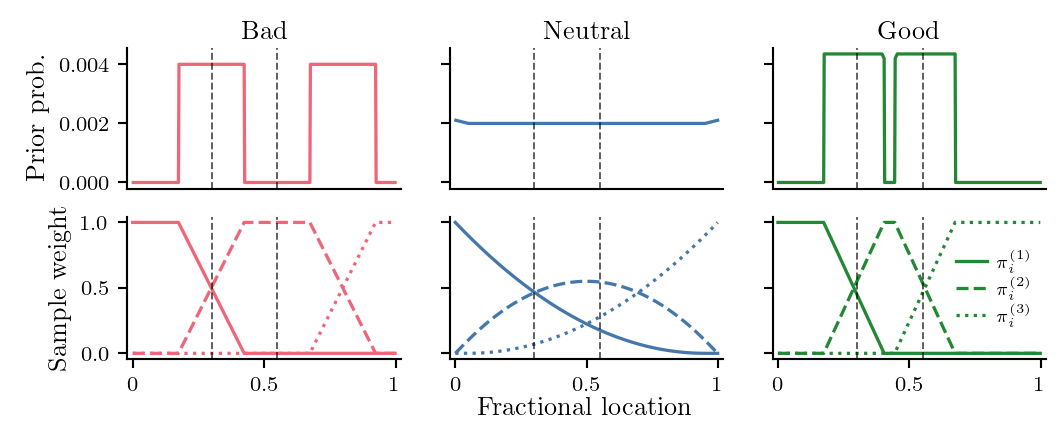

Saved paired Hausdorff errors, with labels sized for the compact side-by-side paper layout.


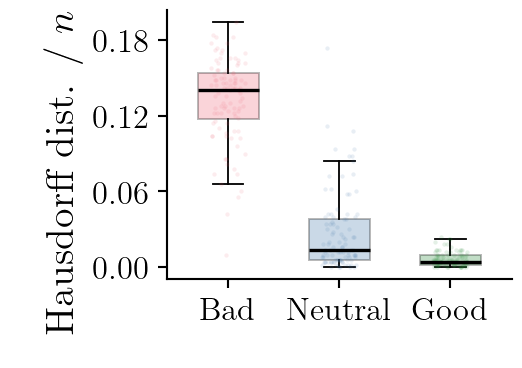

Exported 2 figures to results/consistent_plots_20261102/E_PRIOR/compact_paper; saved inputs unchanged.


In [1]:
# Self-contained compact paper export: plotting saved priors only.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import tools.consistent_plotting as prior_style

prior_style.OUTPUT_DIR = Path('results/consistent_plots_20261102/E_PRIOR/compact_paper')
prior_style.SOURCE_HASHES.clear()
prior_style.FIGURE_AUDIT.clear()
prior_saved = prior_style.load_saved(
    'results/E_PRIOR_jointconfigs_actualgap_100paired_seed20260916.pkl')
prior_n = prior_saved['params']['N']
prior_truth = np.asarray(prior_saved['params']['true_cp']) / prior_n
prior_names = ('Bad', 'Neutral', 'Good')
prior_colors = ('#EE6677', '#4477AA', '#228833')

with plt.rc_context(prior_style.PAPER_STYLE):
    fig, axes = plt.subplots(2, 3, figsize=(5.9, 2.4),
                             sharex=True, sharey='row')
    fig.subplots_adjust(left=.12, right=.985, bottom=.17, top=.89,
                        wspace=.18, hspace=.20)
    for column, (name, color) in enumerate(zip(prior_names, prior_colors)):
        configs = np.asarray(prior_saved['configs'][name], int)
        mass = np.bincount(configs.ravel(), minlength=prior_n) / (2 * len(configs))
        np.testing.assert_allclose(mass.sum(), 1)
        axes[0, column].plot(np.arange(1, prior_n) / prior_n, mass[1:],
                             color=color, lw=1.3)
        axes[0, column].set_title(name, pad=3)
        axes[0, column].tick_params(axis='x', bottom=False)
        axes[0, column].yaxis.set_major_locator(MaxNLocator(3))

        marginal = np.asarray(prior_saved['marginals'][name])
        np.testing.assert_allclose(marginal.sum(axis=0), 1, atol=1e-8)
        for signal, line_style in enumerate(('-', '--', ':')):
            axes[1, column].plot(np.arange(prior_n) / prior_n, marginal[signal],
                                  color=color, ls=line_style, lw=1.3,
                                  label=rf'$\pi_i^{{({signal + 1})}}$')
        axes[1, column].set_ylim(-.04, 1.04)
        axes[1, column].set_yticks([0, .5, 1])
        for ax in axes[:, column]:
            for change in prior_truth:
                ax.axvline(change, color='black', ls='--', lw=.75, alpha=.65)
            ax.set_xlim(-.02, 1.02)
            ax.set_xticks([0, .5, 1], ['0', '0.5', '1'])
    axes[0, 0].set_ylabel('Prior prob.')
    axes[1, 0].set_ylabel('Sample weight')
    axes[1, -1].legend(fontsize=7, loc='center right',
                       handlelength=1.8, handletextpad=.5, labelspacing=.2)
    fig.supxlabel('Fractional location', x=.55, y=.025, fontsize=10.5)
    prior_style.export_plot(fig, 'pooled_prior_and_marginals_compact',
        'Exact prior masses (top) and signal weights (bottom), in a compact shared-axis grid.')
# Larger labels preserve legibility beside the three-column histogram in print.
prior_groups = [[row[name]['conditional_haus'] for row in prior_saved['trials']]
                for name in prior_names]
with plt.rc_context({**prior_style.PAPER_STYLE,
                     'axes.labelsize': 16, 'xtick.labelsize': 13,
                     'ytick.labelsize': 13}):
    fig, ax = plt.subplots(figsize=(2.9, 2.05))
    fig.subplots_adjust(left=.32, right=.98, bottom=.24, top=.97)
    prior_jitter = np.random.default_rng(42)
    for position, (values, color) in enumerate(zip(prior_groups, prior_colors)):
        prior_style.box_group(ax, values, position, color, prior_jitter,
                              width=.55, jitter=.16)
    ax.set_xticks(np.arange(3), prior_names)
    ax.set_xlim(-.55, 2.55)
    ax.set_ylabel(r'Hausdorff dist. / $n$', y=.40)
    ax.yaxis.set_major_locator(MaxNLocator(4))
    prior_style.export_plot(fig, 'prior_location_box_compact',
        'Saved paired Hausdorff errors, with labels sized for the compact side-by-side paper layout.')

prior_style.verify_sources()
